## Лабораторная работа №4. MLOps
### 2. Цель работы и постановка задачи
**Цель работы:** Освоить основы MLOps: учёт и сравнение экспериментов в MLflow, регистрацию и управление версиями моделей, развёртывание сервиса предсказаний с использованием Docker и Docker Compose, проверку его работоспособности, обновление и откат модели.


**Постановка задачи:**
Разработать воспроизводимый проект машинного обучения в соответствии с индивидуальным вариантом задания. Для этого необходимо:

1) Выбрать набор данных, указать источник, определить признаки, целевую переменную и метрики оценки.

2) Подготовить данные и организовать корректное разбиение для обучения, выбора модели и итоговой оценки.

3) Выполнить не менее шести экспериментов с различными алгоритмами или гиперпараметрами. Сохранить в MLflow параметры, метрики, теги и артефакты запусков.

4) Сравнить результаты экспериментов и обосновать выбор модели.

5) Зарегистрировать не менее двух версий модели в MLflow Model Registry и назначить выбранной версии alias champion.

6) Экспортировать модель вместе с необходимыми преобразованиями данных и реализовать API для получения предсказаний.

7) Подготовить Dockerfile, собрать образ и запустить сервис в контейнере.

8) Проверить корректные и некорректные запросы, а также совпадение результатов API с результатами экспортированной модели.

9) Продемонстрировать обновление сервиса и откат к предыдущей версии без повторного обучения.

10) Запустить сервис через Docker Compose, настроить healthcheck и проверить состояние сервиса.

11) Зафиксировать зависимости, исходные данные и разбиение выборки для воспроизведения результатов.

**Вариант 19: Учебная классификация наличия болезни сердца**

Данные и источник: https://archive.ics.uci.edu/dataset/45/heart+disease

Постановка задачи: Признаки → num > 0.

Начальные алгоритмы и критерий: LogisticRegression и RandomForest; macro
F1.

Особенности выполнения: Использовать Cleveland, обработать ?, удалить исходный num из X; медицинские решения не принимать.

### 3. Набор данных и подготовка

**Источник:** UCI Machine Learning Repository, *Heart Disease*, раздел *Processed Cleveland*: https://archive.ics.uci.edu/dataset/45/heart+disease . Использован файл `processed.cleveland.data` (303 наблюдения и 14 исходных столбцов, из которых 13 признаков и `num`). Файл сохранён в `data/raw/` без редактирования содержимого.

**Признаки:**

| Поле | Смысл | Тип |
|---|---|---|
| `age` | Возраст | Числовой |
| `sex` | Пол (кодированное значение) | Категориальный |
| `cp` | Тип боли в груди | Категориальный |
| `trestbps` | Артериальное давление в покое | Числовой |
| `chol` | Холестерин | Числовой |
| `fbs` | Признак высокого сахара натощак | Категориальный |
| `restecg` | Результат ЭКГ в покое | Категориальный |
| `thalach` | Максимальная достигнутая ЧСС | Числовой |
| `exang` | Стенокардия при нагрузке | Категориальный |
| `oldpeak` | Снижение ST при нагрузке | Числовой |
| `slope` | Наклон сегмента ST | Категориальный |
| `ca` | Количество крупных сосудов (код) | Категориальный |
| `thal` | Категория результата исследования thal | Категориальный |

**Целевая переменная:** `num` преобразована к `target = 0`, если `num = 0`, и `target = 1`, если `num > 0`. `num` исключена из `X`, чтобы исключить утечку правильного ответа.

**Пропуски:** строковое обозначение `?` считывается как `NaN`. Числовые признаки заполняются медианой, категориальные - модой. Категории кодируются `OneHotEncoder(handle_unknown="ignore")`, числовые поля стандартизируются `StandardScaler`. Все преобразования включены в единый `Pipeline` и обучаются только на train.

**Разбиение:** `random_state=42`, `stratify=y`. Сначала выделяется 20% для независимого test, затем 25% оставшейся части для validation - итоговые 181 train, 61 validation, 61 test. Test не использовался для выбора гиперпараметров.

In [12]:
from pathlib import Path
import json
import hashlib
import os
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / 'data/raw/processed.cleveland.data').exists():
    raise FileNotFoundError('Открой Notebook из корня проекта ~/lab_4: не найден data/raw/processed.cleveland.data')
DATA_PATH = ROOT / 'data/raw/processed.cleveland.data'
COLUMNS = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']
df = pd.read_csv(DATA_PATH, header=None, names=COLUMNS, sep=',', na_values=['?']).apply(pd.to_numeric, errors='raise')
df['target'] = (df['num'] > 0).astype(int)
print('Размер исходных данных:', df.shape[0], 'строк,', len(COLUMNS), 'исходных столбцов')
print('SHA-256:', hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())
print('Пропуски по столбцам:')
display(df[COLUMNS].isna().sum().to_frame('Количество пропусков'))
print('Дубликаты:', int(df[COLUMNS].duplicated().sum()))
print('Целевая переменная:')
display(df['target'].value_counts().sort_index().rename_axis('Класс').to_frame('Число объектов'))

Размер исходных данных: 303 строк, 14 исходных столбцов
SHA-256: a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f331b622b4efa0427c8
Пропуски по столбцам:


,Количество пропусков
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


Дубликаты: 0
Целевая переменная:


,Число объектов
Класс,
0,164
1,139


In [13]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['num', 'target'])
y = df['target']
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, random_state=42, stratify=y_dev)
display(pd.DataFrame({'Выборка': ['Train', 'Validation', 'Test'], 'Число объектов': [len(X_train),len(X_val),len(X_test)], 'Назначение': ['Обучение', 'Выбор модели', 'Финальная оценка']}))

,Выборка,Число объектов,Назначение
0,Train,181,Обучение
1,Validation,61,Выбор модели
2,Test,61,Финальная оценка


### 4. Программное окружение и структура проекта

Разработка велась в Ubuntu 24.04 LTS под WSL 2, редактор - VS Code с подключением WSL, Python 3.12.3 в виртуальном окружении `.venv`.

| Компонент | Версия |
|---|---|
| MLflow | 3.5.0 |
| scikit-learn | 1.7.2 |
| pandas | 2.3.3 |
| numpy | 2.2.6 |
| matplotlib | 3.10.7 |
| FastAPI | 0.119.0 |
| Uvicorn | 0.37.0 |
| SQLAlchemy | 2.0.44 |

Полный набор установленных транзитивных зависимостей - requirements.lock.txt. При подготовке выполнялись python3 -m venv .venv, source .venv/bin/activate, python -m pip install -r requirements.txt, python -m pip freeze > requirements.lock.txt.

**Структура:** `src/` - скрипты, `data/raw/` - исходный снимок, `mlflow-data/` - база SQLite и артефакты, `exported_model/` - экспортированная модель, `screenshots/` - иллюстрации, `Dockerfile` и `.dockerignore` - Docker, `compose.yaml` - Compose, JSON-файлы - тестовые данные и результаты.

**Рисунок 1 — Структура проекта**

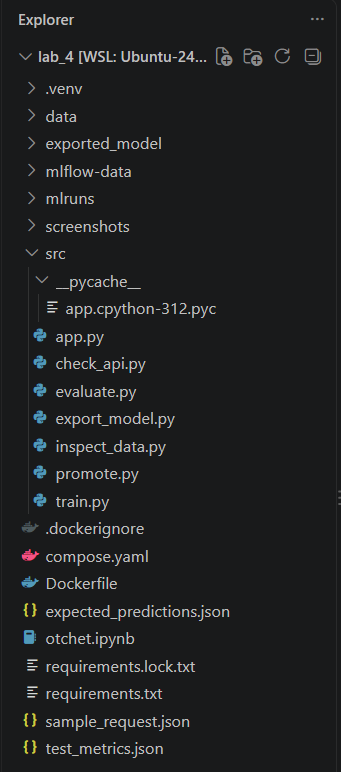

### 5. Последовательность выполнения работы и подтверждения

На начальном этапе был создан каталог проекта `lab_4` и настроено виртуальное окружение Python `.venv`, в которое установлены необходимые библиотеки.

Разработка выполнялась в Visual Studio Code, подключённом к Ubuntu 24.04 через WSL 2. Исходный набор данных UCI Heart Disease (Processed Cleveland) был загружен и сохранён в каталоге `data/raw`.

Для отслеживания экспериментов был развёрнут локальный сервер **MLflow** с использованием базы данных SQLite для хранения информации о запусках и отдельного каталога для артефактов.

Запуск сервера выполнялся командой:

```bash id="d6mbqx"
mlflow server --backend-store-uri sqlite:///mlflow-data/mlflow.db --artifacts-destination ./mlflow-data/artifacts --serve-artifacts --host 127.0.0.1 --port 5000
```

Работоспособность сервера проверялась командой:

```bash id="g2jrg6"
curl -f http://127.0.0.1:5000/health
```

Полученный ответ `OK` подтвердил успешный запуск. Веб-интерфейс MLflow стал доступен по адресу `http://127.0.0.1:5000`.

Обучение и сравнение моделей осуществлялись с помощью скрипта `src/train.py`. Для обеспечения объективности сравнения все шесть экспериментов проводились на одинаковом разбиении данных.

В MLflow для каждого запуска сохранялись:

- **Гиперпараметры модели** — настройки алгоритмов LogisticRegression и RandomForestClassifier.
- **Метрики качества** — `val_accuracy` и `val_f1_macro`.
- **Теги** — контрольная сумма набора данных `dataset_sha256`, назначение эксперимента `purpose` и основная метрика выбора `selection_metric`.
- **Артефакты** — файл разбиения `split.json`, матрица ошибок, исходный код, сведения о зависимостях и обученный Pipeline.


**Рисунок 2 - Подключение VS Code к Ubuntu**

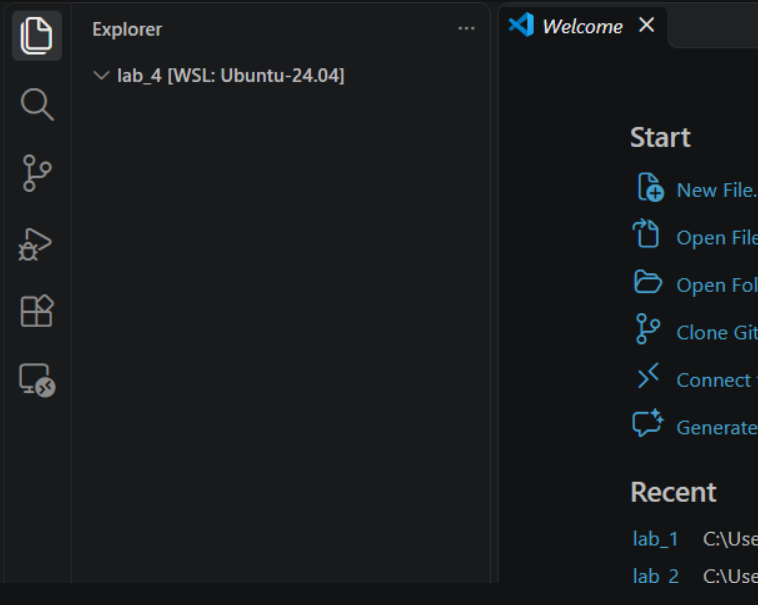

**Рисунок 3 - Сравнение шести запусков MLflow** 

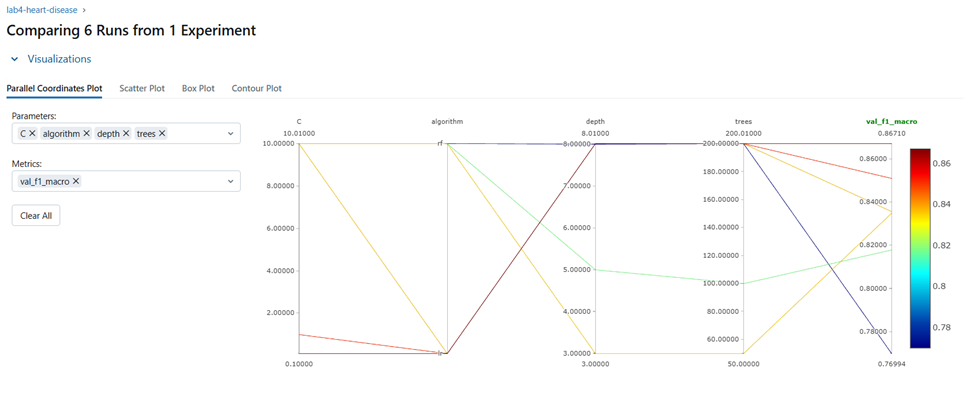


**Рисунок 4 - Сравнительная таблица шести исходных конфигураций с validation-метриками**

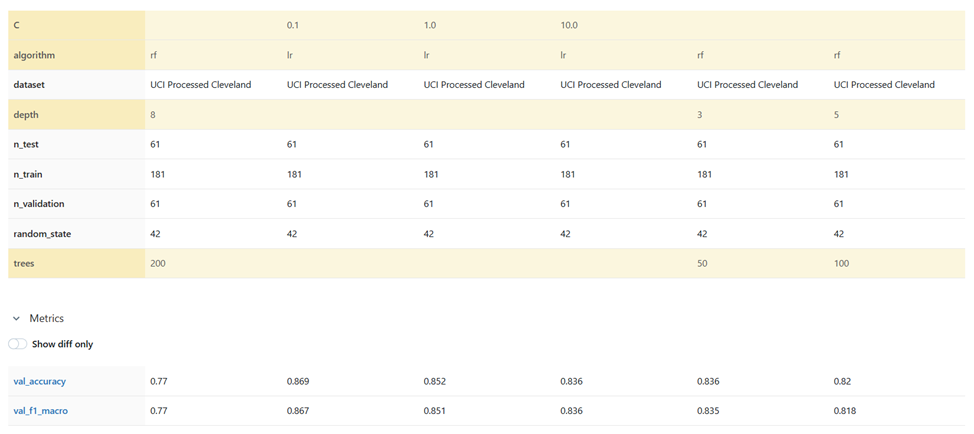

### 6. Сравнение экспериментов

Основной критерий выбора - **максимум `val_f1_macro`** на validation.

**Рисунок 5 - Все эксперименты с алгоритмами, гиперпараметрами и метриками**

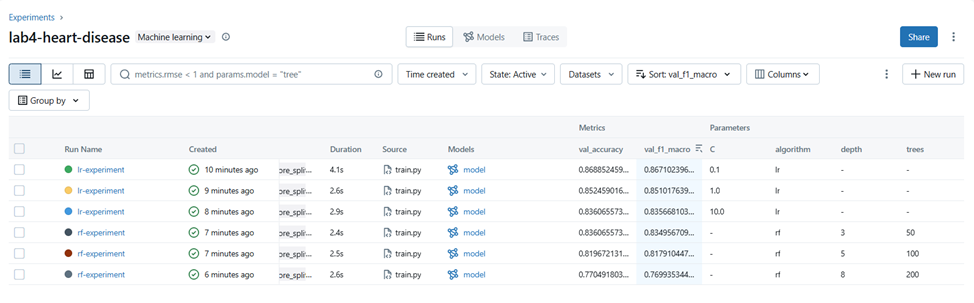

**Рисунок 6 - Идентификаторы запусков**

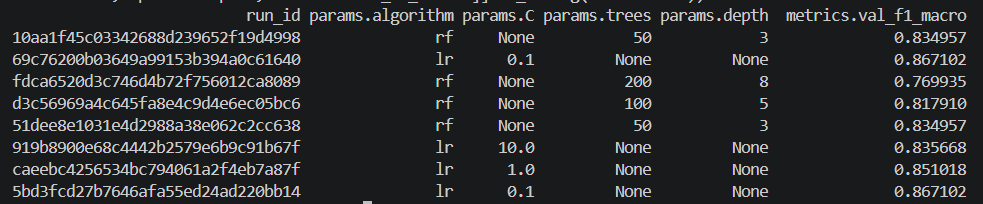

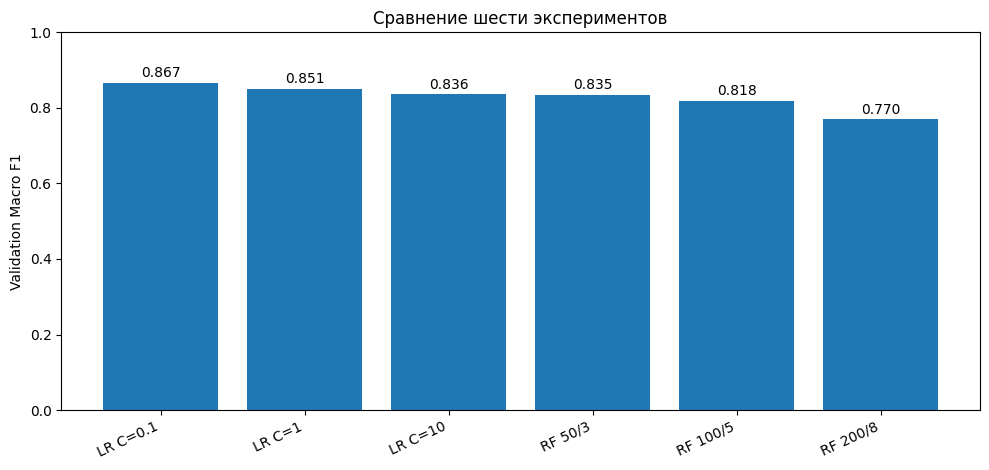

In [14]:
import matplotlib.pyplot as plt

labels = ['LR C=0.1','LR C=1','LR C=10','RF 50/3','RF 100/5','RF 200/8']
f1_values = [0.867,0.851,0.836,0.835,0.818,0.770]
fig, ax=plt.subplots(figsize=(10,4.8))
bars=ax.bar(labels,f1_values)
ax.set_ylabel('Validation Macro F1')
ax.set_title('Сравнение шести экспериментов')
ax.set_ylim(0,1)
for bar,score in zip(bars,f1_values):
    ax.text(bar.get_x()+bar.get_width()/2,score+0.015,f'{score:.3f}',ha='center')
plt.xticks(rotation=25,ha='right')
plt.tight_layout()
plt.show()

Для логистической регрессии изменялся гиперпараметр C (0.1, 1, 10), определяющий силу регуляризации. Для случайного леса изменялись количество деревьев (n_estimators: 50, 100, 200) и максимальная глубина деревьев (max_depth: 3, 5, 8).

Все модели обучались на одинаковой обучающей выборке из 181 наблюдения и оценивались на валидационной выборке из 61 наблюдения. Для обеспечения воспроизводимости использовалось значение random_state=42.

Наилучшие результаты показала модель LogisticRegression с параметром `C=0.1`:

**Accuracy = 0.869 (86.9%)**

**Macro F1 = 0.867 (86.7%)**

При увеличении параметра C качество логистической регрессии на валидационной выборке снижалось. Модели случайного леса показали более низкие значения Macro F1: от 0.770 до 0.835.

По результатам сравнения шести экспериментов наиболее эффективной оказалась логистическая регрессия с параметром C=0.1. Эта модель была выбрана для последующей регистрации в MLflow Model Registry и назначения alias champion.

### 7. Выбор модели и итоговая оценка

Выбрана LogisticRegression при `C=0.1`: `val_f1_macro = 0.867`, `val_accuracy = 0.869`. Среди шести конфигураций эта модель достигла наивысшего macro F1.

На независимой тестовой выборке **61 объект** получены следующие фактические результаты:

- test_accuracy = 0.9016393442622951 (примерно **90,16%**);
- test_f1_macro = 0.9016129032258065 (примерно **90,16%**).

Значение Accuracy показывает, что модель правильно классифицировала 55 из 61 наблюдения. Значение Macro F1 характеризует среднее качество классификации двух классов с учётом точности и полноты.

Результаты итоговой оценки показали, что выбранная модель сохраняет достаточно высокое качество классификации на ранее не использовавшихся данных.

Значения Accuracy и Macro F1 на тестовой выборке оказались выше соответствующих значений на валидационной выборке. Это может быть связано с особенностями случайного разбиения небольшого набора данных и различиями в составе выборок.

При этом результаты на одном тестовом разбиении не гарантируют аналогичное качество на других данных.

Использование отдельной тестовой выборки позволило провести независимую итоговую оценку после выбора модели по валидационным метрикам.

**Рисунок 7 - Результат запуска evaluate.py для экспортированной модели**

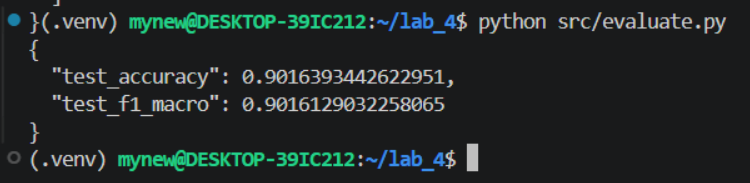

**Дополнительная иллюстрация - матрица ошибок на validation.**

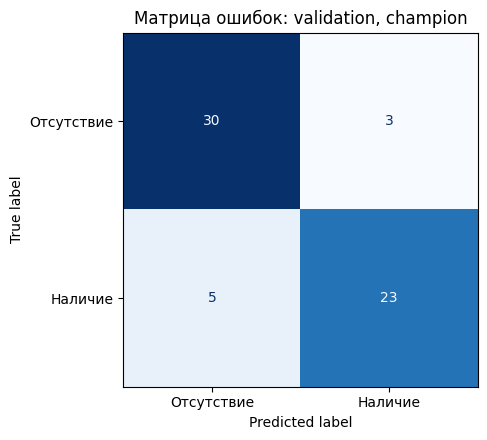

In [15]:
import mlflow.sklearn
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, roc_curve, roc_auc_score

model=mlflow.sklearn.load_model(str(ROOT/'exported_model'))
y_pred_val=model.predict(X_val)
fig,ax=plt.subplots(figsize=(5.5,4.5))
ConfusionMatrixDisplay(confusion_matrix(y_val,y_pred_val),display_labels=['Отсутствие','Наличие']).plot(ax=ax,cmap='Blues',colorbar=False)
ax.set_title('Матрица ошибок: validation, champion')
plt.tight_layout()
plt.show()

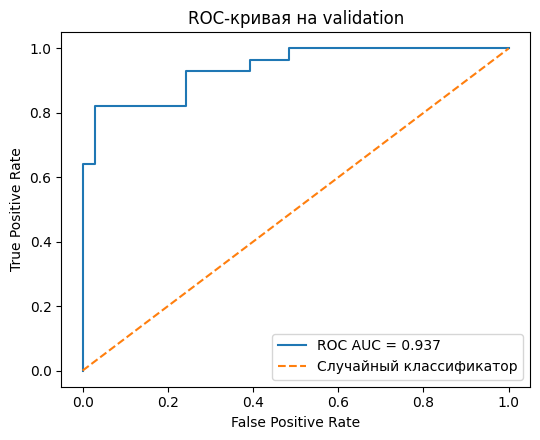

In [16]:
if hasattr(model,'predict_proba'):
    proba=model.predict_proba(X_val)[:,1]
    fpr,tpr,_=roc_curve(y_val,proba)
    auc=roc_auc_score(y_val,proba)
    fig,ax=plt.subplots(figsize=(5.5,4.5))
    ax.plot(fpr,tpr,label=f'ROC AUC = {auc:.3f}')
    ax.plot([0,1],[0,1],'--',label='Случайный классификатор')
    ax.set(xlabel='False Positive Rate',ylabel='True Positive Rate',title='ROC-кривая на validation')
    ax.legend()
    plt.tight_layout()
    plt.show()

### 8. Регистрация версий и назначение alias champion

В MLflow Model Registry создана модель `heart-disease-classifier`. Зарегистрированы два снимка: версия 1 - LogisticRegression (C=0.1), версия 2 - RandomForest (n_estimators=50, max_depth=3). По итогам сравнения лучшей версии 1 назначен alias champion с помощью `src/promote.py`.

`run_id` зарегистрированных снимков:

| Версия | Тип | run_id | Docker-образ |
|---:|---|---|---|
| 1 | LogisticRegression, C=0.1 | `69c76200b03649a99153b394a0c61640` | `heart-api:v1` |
| 2 | RandomForest, trees=50, depth=3 | `10aa1f45c03342688d239652f19d4998` | `heart-api:v2` |

Регистрация двух версий позволила продемонстрировать процесс управления моделями в рамках MLOps.

Для учебной демонстрации обновления сервиса alias champion временно переназначался на версию 2, содержащую RandomForestClassifier.

После проверки обновления был выполнен откат к версии 1, и alias champion снова стал указывать на LogisticRegression.

При этом повторное обучение моделей не потребовалось, поскольку обе версии уже были зарегистрированы и сохранены в MLflow.

**Рисунок 8 - Model Registry**

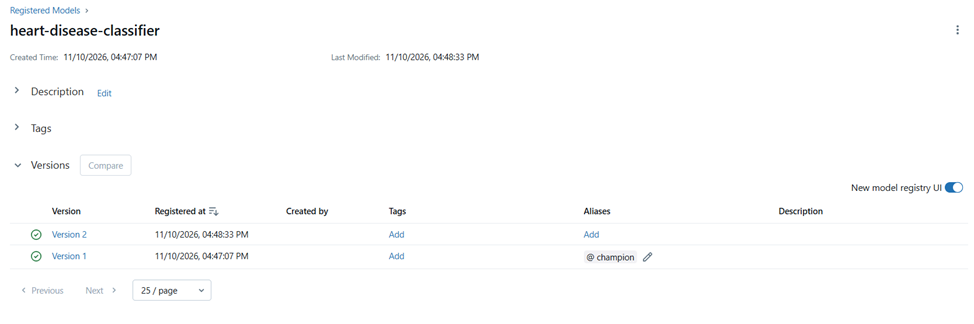

### 9. FastAPI: контракт запросов и проверки

Реализован REST API (`src/app.py`):

| Метод | URL | Результат |
|---|---|---|
| `GET` | `/health` | Состояние загрузки и версия модели |
| `GET` | `/metadata` | Имя модели, версия, run_id, список признаков и классов |
| `POST` | `/predict` | Предсказания и длительность обработки |
| `GET` | `/docs` | Swagger UI |

`POST /predict` принимает JSON вида {"instances": [{"age": 55, ...}]}: список от 1 до 100 объектов; в каждом объекте должны присутствовать **ровно 13 ключей** (`age`, `sex`, `cp`, `trestbps`, `chol`, `fbs`, `restecg`, `thalach`, `exang`, `oldpeak`, `slope`, `ca`, `thal`). Значения - числа или null при пропуске; NaN/бесконечность не должны передаваться в JSON. В ответе - массив predictions, class_names, model_version и latency_ms`.

**Положительный тест:** `POST /predict` возвратил `HTTP 200`, предсказания `[0,1,0]`, классы `absence/presence/absence`, версию `1`, `latency_ms = 7.541` мс в одном из запросов.

**Отрицательные тесты:** неполный набор признаков `{"instances":[{"age":55}]}` и пустой список `{"instances":[]}`должны давать **HTTP 422**.

**Рисунок 9 - Корректный запрос**

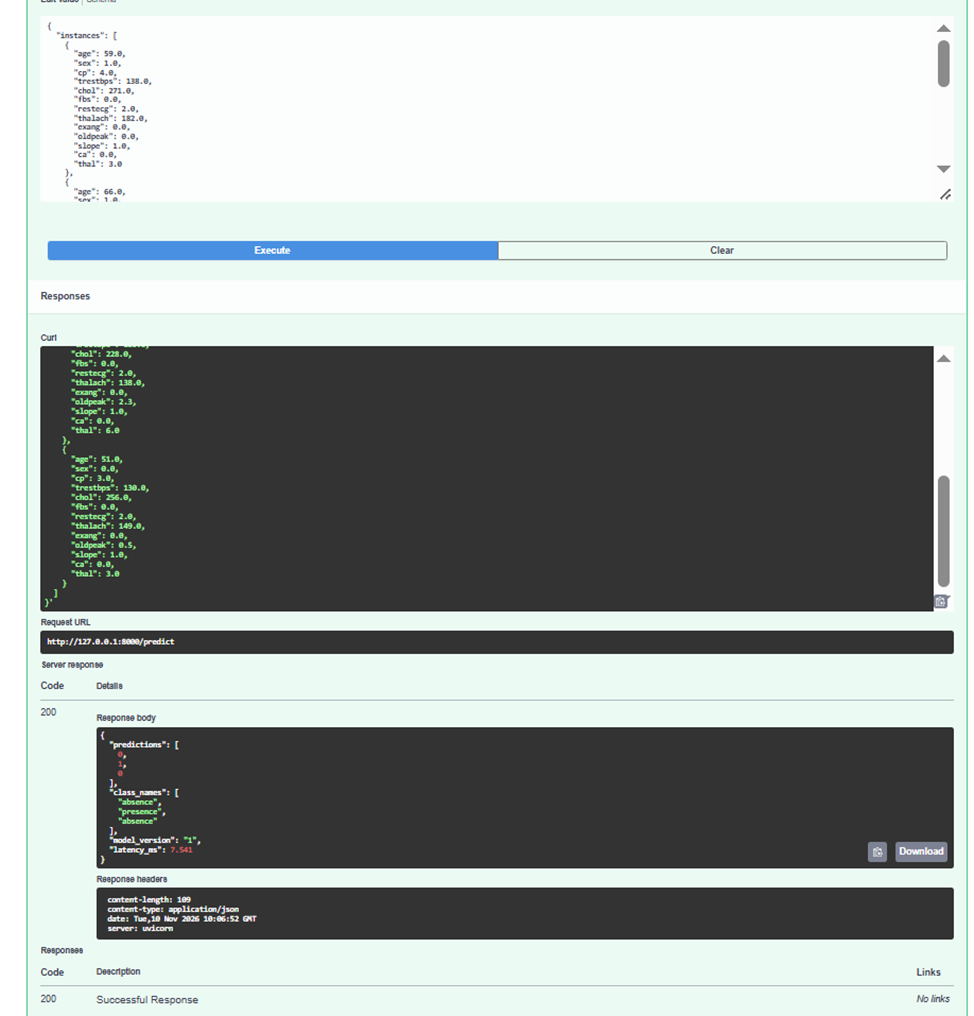

**Рисунок 10 - Некорректный запрос (1 признак вместо 13)**

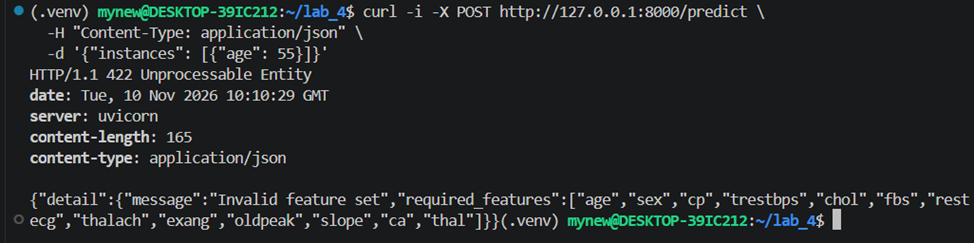

**Рисунок 11 - Некорректный запрос (пустой список)**

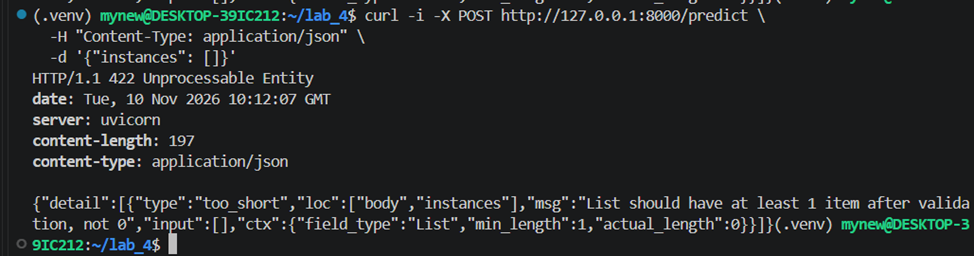


### 10. Сборка, запуск Docker и проверка совпадения

Для развёртывания подготовлены `Dockerfile` и `.dockerignore`. Образ использует `python:3.12-slim`, устанавливает зависимости, копирует `src/app.py` и `exported_model`, запускает `uvicorn` внутри контейнера на `0.0.0.0:8000` от пользователя `appuser`.

Применены команды:

```bash
docker build -t heart-api:v1 .
docker run -d --name heart-api -p 127.0.0.1:8000:8000 heart-api:v1
docker ps
docker logs heart-api
curl -f http://127.0.0.1:8000/health
python src/check_api.py
```

По логам контейнера подтверждены `Application startup complete`, `GET /metadata HTTP/1.1 200 OK` и `POST /predict HTTP/1.1 200 OK`. В финальной проверке `check_api.py` выведено **`PASS: API predictions match exported model`**, версия `1`, ответы `[0,1,0]`.

**Рисунок 12 - Docker-образы**

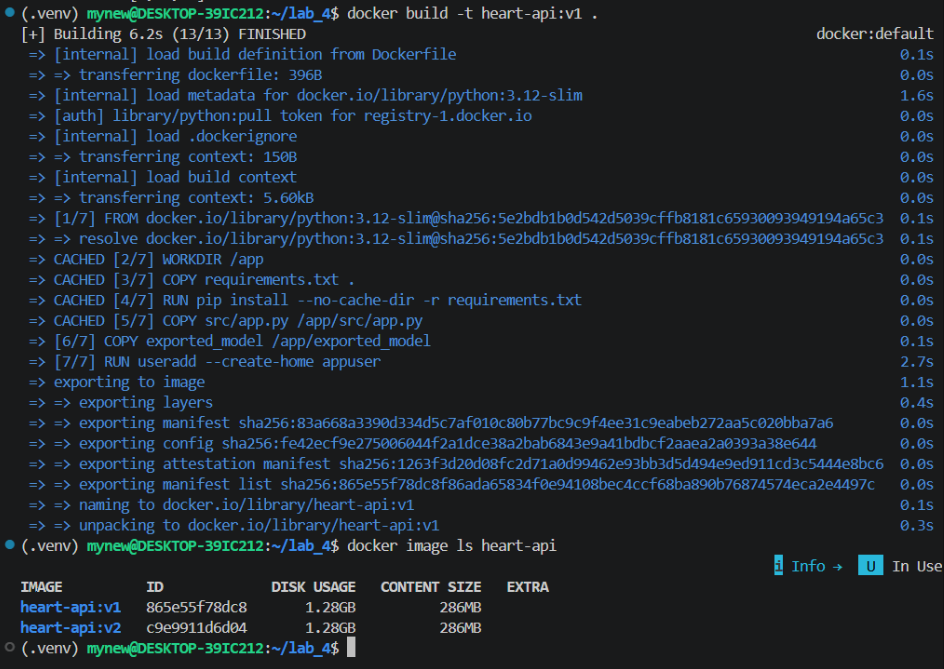


**Рисунок 13 - Запуск Docker-контейнера и проверка совпадения предсказаний с экспортированной моделью**

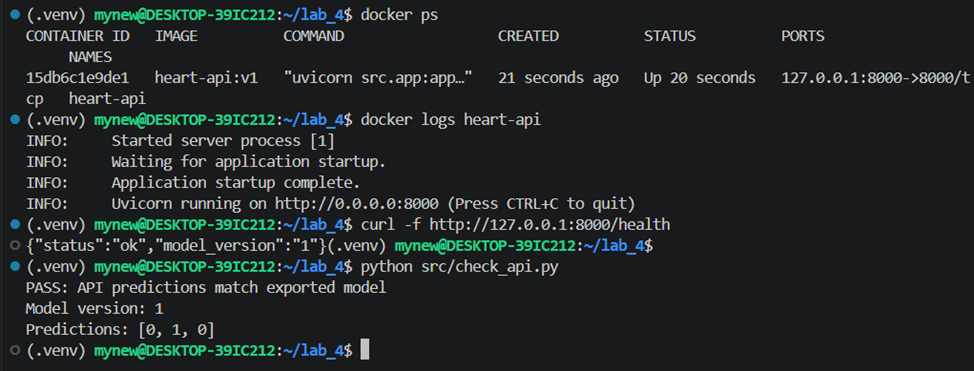

### 11. Обновление и откат модели

Подготовлены два разных Docker-образа и проверено содержимое `metadata.json` внутри каждого:

| Docker image | Model Registry | run_id | Смысл |
|---|---:|---|---|
| heart-api:v1 | 1 | `69c76200b03649a99153b394a0c61640` | Выбранный champion |
| heart-api:v2 | 2 | `10aa1f45c03342688d239652f19d4998` | Альтернативная модель для демонстрации релиза |

Для демонстрации обновления сервиса была выполнена замена модели LogisticRegression (версия 1) на RandomForestClassifier (версия 2).

Сначала alias champion был переключён на версию 2, после чего модель экспортировалась и собирался новый Docker-образ heart-api:v2. Затем контейнер с предыдущей версией был остановлен и заменён новым.

```bash
python src/promote.py --version 2
python src/export_model.py
docker build -t heart-api:v2 .
docker stop heart-api
docker rm heart-api
docker run -d --name heart-api -p 127.0.0.1:8000:8000 heart-api:v2
curl -f http://127.0.0.1:8000/metadata
python src/check_api.py
```

После обновления был выполнен возврат к первоначальной модели LogisticRegression (версия 1).

Контейнер версии 2 был удалён, а вместо него запущен ранее созданный образ heart-api:v1. Alias champion снова назначался версии 1.

```bash
docker stop heart-api
docker rm heart-api
docker run -d --name heart-api -p 127.0.0.1:8000:8000 heart-api:v1
python src/promote.py --version 1
python src/export_model.py
curl -f http://127.0.0.1:8000/metadata
python src/check_api.py
```

После отката API использовал модель версии 1. Проверка check_api.py завершилась успешно: PASS: API predictions match exported model.

Повторное обучение не потребовалось, поскольку обе модели были предварительно зарегистрированы, а Docker-образы сохранены.

**Рисунок 14 - Обновление сервиса до модели версии 2 без повторного обучения**

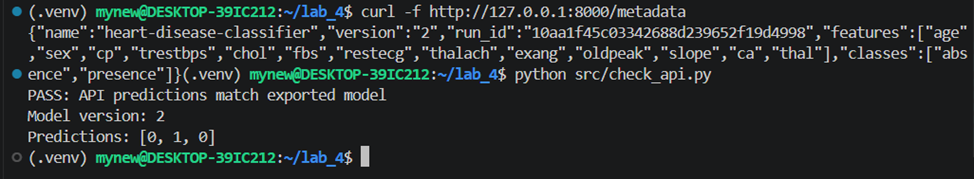

**Рисунок 15 - Откат сервиса с версии 2 на версию 1 без повторного обучения модели**

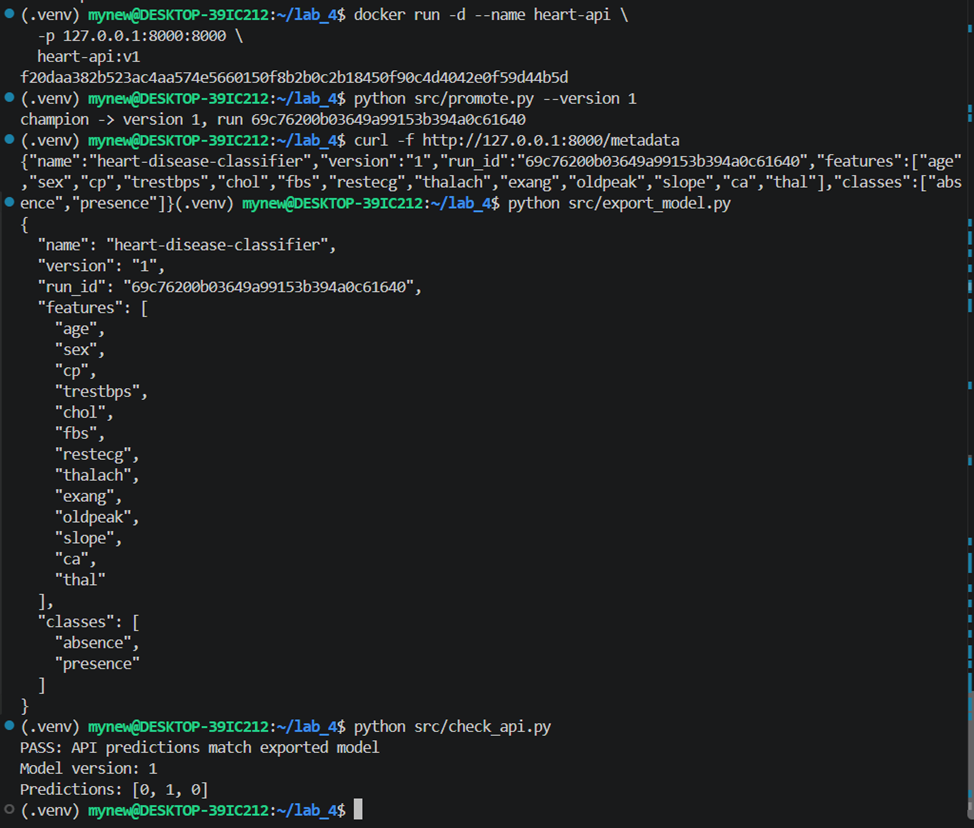

### 12. Docker Compose и healthcheck

Был создан файл compose.yaml, содержащий настройки Docker-контейнера, используемый образ и проверку работоспособности приложения.

Сервис api использует образ heart-api:v1 по умолчанию и доступен по адресу http://127.0.0.1:8000.

Для контроля состояния контейнера настроен healthcheck, который обращается к маршруту /health каждые 10 секунд. Тайм-аут проверки составляет 3 секунды. После трёх последовательных неудачных проверок контейнер получает статус unhealthy.

Запуск и проверка сервиса выполнялись следующими командами:

```bash
docker compose config
docker compose up -d --no-build
docker compose ps
curl -f http://127.0.0.1:8000/health
python src/check_api.py
```

В результате контейнер успешно запустился и получил статус healthy. Проверка check_api.py также завершилась успешно, подтвердив совпадение предсказаний API с экспортированной моделью.

**Рисунок 16 - Запуск сервиса классификации наличия болезни сердца через Docker Compose и проверка состояния healthy**

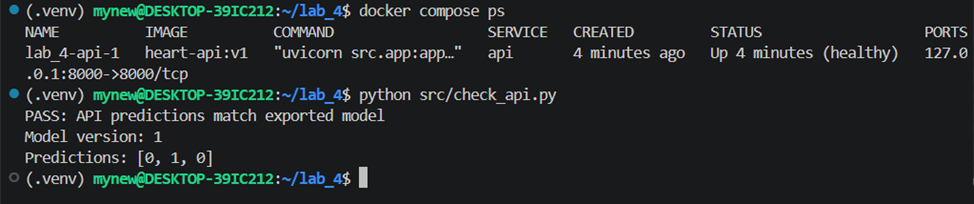



### 13. Выводы

В лабораторной работе выполнен учебный цикл MLOps для бинарной классификации на датасете Heart Disease (Processed Cleveland). Организовано воспроизводимое разбиение train/validation/test, обработка пропусков и кодирование признаков внутри Pipeline. Проведено шесть отслеживаемых в MLflow экспериментов с сохранением параметров, метрик и артефактов. Лучшая модель по `val_f1_macro` - **LogisticRegression при C=0.1** (`0.867`). На отложенном test получены **accuracy = 0.9016** и **macro F1 = 0.9016**.

В Model Registry зарегистрированы две версии, alias `champion` назначен версии 1. Модель экспортирована в составе Pipeline и опубликована через FastAPI. Сервис контейнеризирован в Docker, подготовлены образы `heart-api:v1` и `heart-api:v2`, поддерживающие обновление и откат без повторного обучения. Итоговый запуск через Docker Compose показал статус `healthy`, а автоматическая проверка подтвердила идентичность ответов API и экспортированной модели.


### 14. Список использованных источников.
1) Scikit-learn: машинное обучение в Python [Электронный ресурс]. - URL: https://scikit-learn.ru/stable/ - Документация по алгоритмам классификации, предобработке данных и оценке качества моделей.

2) Microsoft Learn. Отслеживание разработки моделей с помощью MLflow [Электронный ресурс]. - URL: https://learn.microsoft.com/ru-ru/azure/databricks/mlflow/tracking - Описание экспериментов, параметров, метрик и артефактов MLflow.

3) Microsoft Learn. Запрос и сравнение экспериментов с помощью MLflow [Электронный ресурс]. - URL: https://learn.microsoft.com/ru-ru/azure/machine-learning/how-to-track-experiments-mlflow?view=azureml-api-2 - Работа с запусками экспериментов и сравнение результатов.

### 15. Приложение



In [18]:
from pathlib import Path
from IPython.display import display, Markdown

files = [
    "src/inspect_data.py",
    "src/train.py",
    "src/promote.py",
    "src/export_model.py",
    "src/evaluate.py",
    "src/app.py",
    "src/check_api.py",
    "requirements.txt",
    "requirements.lock.txt",
    "Dockerfile",
    ".dockerignore",
    "compose.yaml",
    "sample_request.json",
    "expected_predictions.json"
]

for filename in files:
    path = Path(filename)

    if path.exists():
        content = path.read_text(encoding="utf-8")
        language = "python" if path.suffix == ".py" else "text"
        display(Markdown(f"### {filename}\n\n```{language}\n{content}\n```"))
    else:
        print(f"Файл не найден: {filename}")

### src/inspect_data.py

```python

from pathlib import Path
import pandas as pd

DATA_PATH = (
    Path(__file__).resolve().parent.parent
    / "data"
    / "raw"
    / "processed.cleveland.data"
)

COLUMNS = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal",
    "num",
]

df = pd.read_csv(
    DATA_PATH,
    header=None,
    names=COLUMNS,
    sep=",",
    na_values=["?"],
)

df = df.apply(pd.to_numeric, errors="raise")

print("Размер датасета:")
print(df.shape)

print("\nПервые пять строк:")
print(df.head())

print("\nТипы столбцов:")
print(df.dtypes)

print("\nКоличество пропусков:")
print(df.isna().sum())

print("\nКоличество дубликатов:")
print(df.duplicated().sum())

print("\nРаспределение исходной переменной num:")
print(df["num"].value_counts().sort_index())

if df["num"].isna().any():
    raise ValueError("Целевая переменная содержит пропуски")

df["target"] = (df["num"] > 0).astype(int)

X = df.drop(columns=["num", "target"])
y = df["target"]

print("\nРаспределение бинарной целевой переменной:")
print(y.value_counts().sort_index())

print("\nРазмер матрицы признаков X:")
print(X.shape)

print("\nРазмер целевой переменной y:")
print(y.shape)

print("\nОписательная статистика:")
print(X.describe().round(2))

```

### src/train.py

```python

import argparse
import hashlib
import json
import os
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

import mlflow
import mlflow.sklearn
import pandas as pd

from mlflow.models import infer_signature
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
)

ROOT = Path(__file__).resolve().parent.parent

DATA_PATH = ROOT / "data/raw/processed.cleveland.data"

COLUMNS = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "num"
]

NUMERIC_FEATURES = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

CATEGORICAL_FEATURES = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

parser = argparse.ArgumentParser()

parser.add_argument(
    "--algorithm",
    choices=["lr", "rf"],
    required=True
)

parser.add_argument("--c", type=float, default=1.0)
parser.add_argument("--trees", type=int, default=100)
parser.add_argument("--depth", type=int, default=5)
parser.add_argument("--register", action="store_true")

args = parser.parse_args()

mlflow.set_tracking_uri(
    os.getenv(
        "MLFLOW_TRACKING_URI",
        "http://127.0.0.1:5000"
    )
)

mlflow.set_experiment("lab4-heart-disease")

df = pd.read_csv(
    DATA_PATH,
    header=None,
    names=COLUMNS,
    sep=",",
    na_values=["?"]
)

df = df.apply(pd.to_numeric, errors="raise")

if df["num"].isna().any():
    raise ValueError("Пропуски в целевой переменной")

X = df.drop(columns=["num"])
y = (df["num"] > 0).astype(int)

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.25,
    random_state=42,
    stratify=y_dev
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, NUMERIC_FEATURES),
    ("cat", categorical_pipeline, CATEGORICAL_FEATURES)
])

if args.algorithm == "lr":
    classifier = LogisticRegression(
        C=args.c,
        max_iter=2000,
        random_state=42
    )
else:
    classifier = RandomForestClassifier(
        n_estimators=args.trees,
        max_depth=args.depth,
        random_state=42,
        n_jobs=1
    )

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

data_hash = hashlib.sha256(
    DATA_PATH.read_bytes()
).hexdigest()

with mlflow.start_run(
    run_name=f"{args.algorithm}-experiment"
) as run:

    mlflow.log_params({
        "algorithm": args.algorithm,
        "random_state": 42,
        "n_train": len(X_train),
        "n_validation": len(X_val),
        "n_test": len(X_test),
        "dataset": "UCI Processed Cleveland"
    })

    if args.algorithm == "lr":
        mlflow.log_param("C", args.c)
    else:
        mlflow.log_params({
            "trees": args.trees,
            "depth": args.depth
        })

    mlflow.set_tags({
        "purpose": "lab4-variant19",
        "dataset_sha256": data_hash,
        "selection_metric": "val_f1_macro"
    })

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    accuracy = accuracy_score(y_val, predictions)
    f1_macro = f1_score(
        y_val, predictions, average="macro"
    )

    mlflow.log_metrics({
        "val_accuracy": accuracy,
        "val_f1_macro": f1_macro
    })

    mlflow.log_input(
        mlflow.data.from_pandas(
            df,
            source=(
                "https://archive.ics.uci.edu/"
                "dataset/45/heart+disease"
            ),
            targets="num"
        ),
        context="full_dataset_before_split"
    )

    split_info = {
        "train_indices": X_train.index.tolist(),
        "validation_indices": X_val.index.tolist(),
        "test_indices": X_test.index.tolist(),
        "features": X.columns.tolist(),
        "target_definition": "num > 0",
        "random_state": 42
    }

    mlflow.log_dict(split_info, "split.json")

    mlflow.log_artifact(
        str(Path(__file__).resolve()),
        artifact_path="source"
    )

    mlflow.log_artifact(
        str(ROOT / "requirements.txt"),
        artifact_path="source"
    )

    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        predictions,
        ax=ax
    )

    mlflow.log_figure(
        fig,
        "validation_confusion_matrix.png"
    )

    plt.close(fig)

    signature = infer_signature(
        X_train,
        model.predict(X_train)
    )

    model_info = mlflow.sklearn.log_model(
        model,
        name="model",
        input_example=X_train.head(2),
        signature=signature,
        pip_requirements=(
            ROOT / "requirements.txt"
        ).read_text().splitlines()
    )

    print("RUN_ID:", run.info.run_id)
    print("MODEL_URI:", model_info.model_uri)
    print("VAL_ACCURACY:", accuracy)
    print("VAL_F1_MACRO:", f1_macro)

    if args.register:
        version = mlflow.register_model(
            model_info.model_uri,
            "heart-disease-classifier"
        )

        print("REGISTERED_VERSION:", version.version)

```

### src/promote.py

```python

import argparse
import os

import mlflow
from mlflow import MlflowClient

parser = argparse.ArgumentParser()

parser.add_argument("--version", required=True)
parser.add_argument("--alias", default="champion")

args = parser.parse_args()

mlflow.set_tracking_uri(
    os.getenv(
        "MLFLOW_TRACKING_URI",
        "http://127.0.0.1:5000"
    )
)

client = MlflowClient()

model_version = client.get_model_version(
    "heart-disease-classifier",
    args.version
)

client.set_registered_model_alias(
    "heart-disease-classifier",
    args.alias,
    args.version
)

print(
    f"{args.alias} -> version {model_version.version}, "
    f"run {model_version.run_id}"
)

```

### src/export_model.py

```python

import json
import os
import shutil
from pathlib import Path

import mlflow
import mlflow.sklearn
import pandas as pd

from mlflow import MlflowClient
from sklearn.model_selection import train_test_split

ROOT = Path(__file__).resolve().parent.parent
DATA_PATH = ROOT / "data/raw/processed.cleveland.data"

COLUMNS = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "num"
]

mlflow.set_tracking_uri(
    os.getenv(
        "MLFLOW_TRACKING_URI",
        "http://127.0.0.1:5000"
    )
)

client = MlflowClient()

version = client.get_model_version_by_alias(
    "heart-disease-classifier",
    "champion"
)

model = mlflow.sklearn.load_model(
    f"models:/heart-disease-classifier/{version.version}"
)

export_path = ROOT / "exported_model"

if export_path.exists():
    shutil.rmtree(export_path)

mlflow.sklearn.save_model(
    model,
    str(export_path),
    pip_requirements=(
        ROOT / "requirements.txt"
    ).read_text().splitlines()
)

df = pd.read_csv(
    DATA_PATH,
    header=None,
    names=COLUMNS,
    na_values=["?"]
)

df = df.apply(pd.to_numeric, errors="raise")

X = df.drop(columns=["num"])
y = (df["num"] > 0).astype(int)

_, X_test, _, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

metadata = {
    "name": "heart-disease-classifier",
    "version": str(version.version),
    "run_id": version.run_id,
    "features": X.columns.tolist(),
    "classes": ["absence", "presence"]
}

(export_path / "metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8"
)

request = {
    "instances": X_test.iloc[:3]
        .astype(object)
        .where(pd.notna(X_test.iloc[:3]), None)
        .to_dict(orient="records")
}

(ROOT / "sample_request.json").write_text(
    json.dumps(request, indent=2),
    encoding="utf-8"
)

predictions = model.predict(X_test.iloc[:3])

(ROOT / "expected_predictions.json").write_text(
    json.dumps(predictions.astype(int).tolist(), indent=2),
    encoding="utf-8"
)

print(json.dumps(metadata, indent=2))

```

### src/evaluate.py

```python

import json
from pathlib import Path

import mlflow.sklearn
import pandas as pd

from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split

ROOT = Path(__file__).resolve().parent.parent
DATA_PATH = ROOT / "data/raw/processed.cleveland.data"

COLUMNS = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "num"
]

model = mlflow.sklearn.load_model(
    str(ROOT / "exported_model")
)

df = pd.read_csv(
    DATA_PATH,
    header=None,
    names=COLUMNS,
    na_values=["?"]
)

df = df.apply(pd.to_numeric, errors="raise")

X = df.drop(columns=["num"])
y = (df["num"] > 0).astype(int)

_, X_test, _, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

predictions = model.predict(X_test)

metrics = {
    "test_accuracy": float(
        accuracy_score(y_test, predictions)
    ),
    "test_f1_macro": float(
        f1_score(y_test, predictions, average="macro")
    )
}

(ROOT / "test_metrics.json").write_text(
    json.dumps(metrics, indent=2),
    encoding="utf-8"
)

print(json.dumps(metrics, indent=2))

```

### src/app.py

```python

import json
import logging
import os
import time
from pathlib import Path

import mlflow.sklearn
import numpy as np
import pandas as pd

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

ROOT = Path(__file__).resolve().parent.parent

MODEL_PATH = Path(
    os.getenv(
        "MODEL_PATH",
        str(ROOT / "exported_model")
    )
)

app = FastAPI(
    title="Heart Disease Classifier",
    version="1.0.0"
)

model = mlflow.sklearn.load_model(str(MODEL_PATH))

metadata = json.loads(
    (MODEL_PATH / "metadata.json").read_text(
        encoding="utf-8"
    )
)

logger = logging.getLogger("uvicorn.error")


class PredictRequest(BaseModel):
    instances: list[dict[str, float | None]] = Field(
        min_length=1,
        max_length=100
    )


@app.get("/health")
def health():
    return {
        "status": "ok",
        "model_version": metadata["version"]
    }


@app.get("/metadata")
def get_metadata():
    return metadata


@app.post("/predict")
def predict(body: PredictRequest):
    start = time.perf_counter()

    required = set(metadata["features"])

    for row in body.instances:
        if set(row.keys()) != required:
            raise HTTPException(
                status_code=422,
                detail={
                    "message": "Invalid feature set",
                    "required_features": metadata["features"]
                }
            )

    X = pd.DataFrame(body.instances)
    X = X[metadata["features"]]
    X = X.astype(float)

    values = X.to_numpy(dtype=float)

    if np.isinf(values).any():
        raise HTTPException(
            status_code=422,
            detail="Feature values must be finite or null"
        )

    predictions = model.predict(X).astype(int).tolist()

    elapsed = (time.perf_counter() - start) * 1000

    logger.info(
        "model_version=%s rows=%d latency_ms=%.3f",
        metadata["version"],
        len(X),
        elapsed
    )

    return {
        "predictions": predictions,
        "class_names": [
            metadata["classes"][p]
            for p in predictions
        ],
        "model_version": metadata["version"],
        "latency_ms": round(elapsed, 3)
    }

```

... (4 outputs left out)

### .dockerignore

```text

.venv
.git
__pycache__
mlflow-data
mlruns
mlartifacts
mlflow.db
screenshots
data
requirements.lock.txt
*.zip

```

### compose.yaml

```text

services:
  api:
    image: heart-api:${IMAGE_TAG:-v1}
    build: .
    ports:
      - "127.0.0.1:8000:8000"
    restart: unless-stopped
    healthcheck:
      test:
        - CMD
        - python
        - -c
        - "import urllib.request; urllib.request.urlopen('http://127.0.0.1:8000/health')"
      interval: 10s
      timeout: 3s
      retries: 3
      start_period: 20s

```

### sample_request.json

```text
{
  "instances": [
    {
      "age": 59.0,
      "sex": 1.0,
      "cp": 4.0,
      "trestbps": 138.0,
      "chol": 271.0,
      "fbs": 0.0,
      "restecg": 2.0,
      "thalach": 182.0,
      "exang": 0.0,
      "oldpeak": 0.0,
      "slope": 1.0,
      "ca": 0.0,
      "thal": 3.0
    },
    {
      "age": 66.0,
      "sex": 1.0,
      "cp": 4.0,
      "trestbps": 160.0,
      "chol": 228.0,
      "fbs": 0.0,
      "restecg": 2.0,
      "thalach": 138.0,
      "exang": 0.0,
      "oldpeak": 2.3,
      "slope": 1.0,
      "ca": 0.0,
      "thal": 6.0
    },
    {
      "age": 51.0,
      "sex": 0.0,
      "cp": 3.0,
      "trestbps": 130.0,
      "chol": 256.0,
      "fbs": 0.0,
      "restecg": 2.0,
      "thalach": 149.0,
      "exang": 0.0,
      "oldpeak": 0.5,
      "slope": 1.0,
      "ca": 0.0,
      "thal": 3.0
    }
  ]
}
```

### expected_predictions.json

```text
[
  0,
  1,
  0
]
```